# Logistiklabb 2026

**Grupp:** Rikard & David



In [228]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 2)

---
# 1. Lagerstyrning och produktion
## 1a) Exponentiell utjämning

Prognosen uppdateras med

$$u(t) = a\,d(t) + (1-a)\,u(t-1), \qquad 0 \le a \le 1,$$

där $u(t-1)$ är prognosen för månad $t$ (gjord månaden innan) och $u(0)=50$ är startskattningen (prognos för januari). Prognosen för december är alltså $u(\text{nov})$.

Prognosfelet mäts med MAPE över de 11 månader där vi har utfall:

$$\text{MAPE} = \frac{100}{n}\sum_{t=1}^{n}\frac{|d(t)-u(t-1)|}{d(t)}\;\%.$$

In [229]:
manader = ["jan","feb","mar","apr","maj","jun","jul","aug","sep","okt","nov","dec"]
d = np.array([52, 51, 60, 46, 70, 50, 39, 48, 60, 70, 60], dtype=float)
u0 = 50.0

def utjamning(a, d=d, u0=u0):
    # Returnerar prognoserna u(t-1) för jan..dec (12 värden)
    u = [u0]
    for dt in d:
        u.append(a*dt + (1-a)*u[-1])
    return np.array(u)

def mape(a):
    u = utjamning(a)
    return 100*np.mean(np.abs(d - u[:-1]) / d)

alfa = np.round(np.arange(0, 1.01, 0.1), 1)
tabell = pd.DataFrame({
    "a": alfa,
    "Prognos dec": [utjamning(a)[-1] for a in alfa],
    "MAPE (%)": [mape(a) for a in alfa],
})
tabell

,a,Prognos dec,MAPE (%)
0,0.0,50.00,14.00
1,0.1,54.15,14.45
2,0.2,56.66,14.93
3,0.3,58.48,15.26
4,0.4,59.90,15.37
5,0.5,60.94,16.20
6,0.6,61.56,17.31
7,0.7,61.74,18.29
8,0.8,61.49,19.11
9,0.9,60.89,19.79


In [230]:
# Prognoserna månad för månad för några värden på a
prognoser = pd.DataFrame({"d(t)": list(d) + [np.nan]}, index=manader)
for a in [0.1, 0.3, 0.5, 0.9]:
    prognoser[f"u(t-1), a={a}"] = utjamning(a)
prognoser.T

,jan,feb,mar,apr,maj,jun,jul,aug,sep,okt,nov,dec
d(t),52.0,51.0,60.00,46.00,70.00,50.00,39.00,48.00,60.00,70.00,60.00,NaN
"u(t-1), a=0.1",50.0,50.2,50.28,51.25,50.73,52.65,52.39,51.05,50.74,51.67,53.50,54.15
"u(t-1), a=0.3",50.0,50.6,50.72,53.50,51.25,56.88,54.81,50.07,49.45,52.61,57.83,58.48
"u(t-1), a=0.5",50.0,51.0,51.00,55.50,50.75,60.38,55.19,47.09,47.55,53.77,61.89,60.94
"u(t-1), a=0.9",50.0,51.8,51.08,59.11,47.31,67.73,51.77,40.28,47.23,58.72,68.87,60.89


Lägst MAPE = 14.00 % vid a = 0.000, prognos dec = 50.00


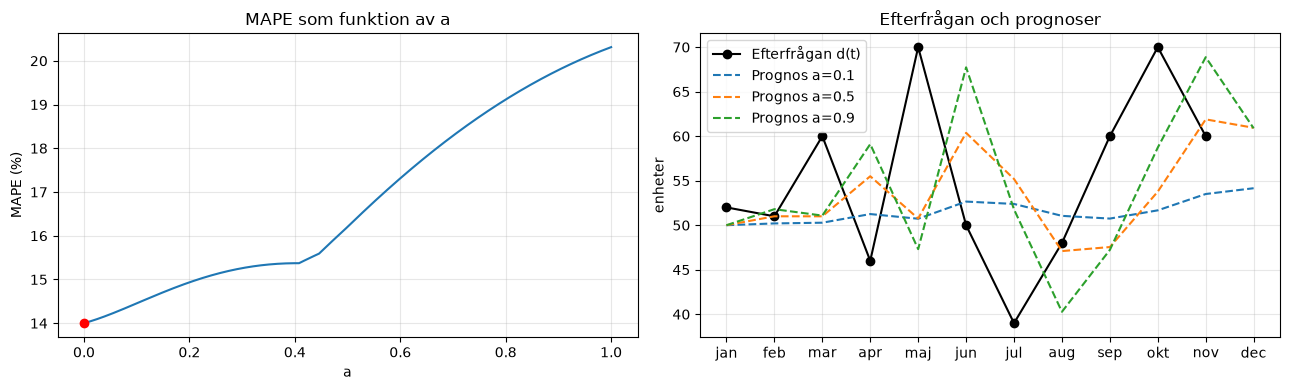

In [231]:
fin = np.linspace(0, 1, 1001)
m = np.array([mape(a) for a in fin])
a_best = fin[m.argmin()]
print(f"Lägst MAPE = {m.min():.2f} % vid a = {a_best:.3f}, prognos dec = {utjamning(a_best)[-1]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(fin, m)
ax[0].scatter([a_best], [m.min()], color="red", zorder=3)
ax[0].set(xlabel="a", ylabel="MAPE (%)", title="MAPE som funktion av a")
ax[0].grid(alpha=.3)

ax[1].plot(manader[:11], d, "ko-", label="Efterfrågan d(t)")
for a in [0.1, 0.5, 0.9]:
    ax[1].plot(manader, utjamning(a), "--", label=f"Prognos a={a}")
ax[1].set(title="Efterfrågan och prognoser", ylabel="enheter")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Analys (att fylla i / diskutera):**
- *Litet a* → prognosen lägger lite vikt vid senaste utfallet och mycket vid historiken: jämn, trög prognos som filtrerar bort slumpvariation. $a=0$ ger alltid 50.
- *Stort a* → prognosen följer senaste utfallet nära: snabb reaktion på förändringar men också på brus. $a=1$ ger "naiv prognos" $u(t)=d(t)$.
- Efterfrågan här svänger kraftigt utan tydlig trend, så … *(kommentera vilket a som gav lägst MAPE och varför)*.

### Härledning av den rekursiva formeln

Utgå från den viktade summan av hela tidsserien där vikterna avtar geometriskt:

$$u(t) = a\,d(t) + a(1-a)\,d(t-1) + a(1-a)^2 d(t-2) + \dots + (1-a)^t u(0)
= a\sum_{k=0}^{t-1}(1-a)^k d(t-k) + (1-a)^t u(0).$$

Skriv motsvarande uttryck för $u(t-1)$ och multiplicera med $(1-a)$:

$$(1-a)\,u(t-1) = a\sum_{k=0}^{t-2}(1-a)^{k+1} d(t-1-k) + (1-a)^t u(0) = a\sum_{k=1}^{t-1}(1-a)^{k} d(t-k) + (1-a)^t u(0).$$

Det är exakt alla termer i $u(t)$ utom den första, $a\,d(t)$. Alltså

$$u(t) = a\,d(t) + (1-a)\,u(t-1).$$

Vikterna $a(1-a)^k$ summerar (tillsammans med $(1-a)^t$) till 1, så det är ett riktigt viktat medelvärde där äldre observationer väger exponentiellt mindre.

## 1b) ABC-analys

Lagervärde per artikel = antal $\times$ medelkostnad. Artiklarna sorteras efter lagervärde och den kumulativa andelen beräknas för att göra analysen. Gränsen dras vid A = de första 80 % av värdet, B = 80-95 % och C de sista 5 %.

### Lösning i Excel

Analysen är gjord i Excel och arbetsgången är följande:

1. Lagervärdet räknas ut för varje artikel och tabellen sorteras fallande efter lagervärde.
2. Lagervärdet summeras kumulativt nedåt i tabellen.
3. Den kumulativa summan delas med det totala lagervärdet, vilket ger kumulativ andel.


| Kolumn | Innehåll | Formel (rad 3 som exempel) |
|---|---|---|
| D | Lagervärde | `=B3*C3` (antal × medelkostnad) |
| E | Kumulativt lagervärde | `=E2+D3` (i E2: `=D2`) |
| F | Kumulativ andel | `=E3/E26` (E26 = totalt lagervärde) |
| G | ABC-klass | `=OM(F3<=0,8; "A"; OM(F3<=0,95; "B"; "C"))` |

En vara klassas som A om kumulativa andelen är mindre än 80 %, B om den är mindre än 95% och annars som C.

Nedan läses Excels resultat in och formlerna hämtas direkt ur filen.

In [232]:
import openpyxl

# Värdena som Excel har räknat fram
abc = pd.read_excel("abc.xlsx", sheet_name="Blad1", header=0, usecols="A:G", nrows=25)
abc.columns = ["vara", "antal", "medelkostnad", "lagervärde", "kumulativt", "kumulativ", "klass"]
abc.index = range(1, len(abc) + 1)

# Formlerna som står i Excel-arket (rad 3 som exempel)
ws = openpyxl.load_workbook("abc.xlsx")["Blad1"]
for kol in "DEFG":
    print(f"{kol}3: {ws[f'{kol}3'].value}")

abc.style.format({"lagervärde": "{:,.0f}", "kumulativt": "{:,.0f}", "kumulativ": "{:.2%}"})

D3: =B3*C3
E3: =E2+D3
F3: =E3/$E$26
G3: =IF(F3<=0.8,"A",IF(F3<=0.95,"B","C"))


,vara,antal,medelkostnad,lagervärde,kumulativt,kumulativ,klass
1,15,84000,30,"2,520,000","2,520,000",39.91%,A
2,19,21770,35,"761,950","3,281,950",51.98%,A
3,13,1306,500,"653,000","3,934,950",62.32%,A
4,3,70000,5,"350,000","4,284,950",67.87%,A
5,10,19593,13,"254,709","4,539,659",71.90%,A
6,1,700,342,"239,400","4,779,059",75.69%,A
7,9,10500,21,"220,500","4,999,559",79.18%,A
8,4,68000,3,"204,000","5,203,559",82.42%,B
9,12,19593,10,"195,930","5,399,489",85.52%,B
10,2,800,200,"160,000","5,559,489",88.05%,B


In [233]:
sammanfattning = abc.groupby("klass").agg(
    antal_artiklar=("vara", "count"),
    lagervärde=("lagervärde", "sum"),
)
sammanfattning["andel artiklar (%)"] = 100 * sammanfattning["antal_artiklar"] / len(abc)
sammanfattning["andel lagervärde (%)"] = 100 * sammanfattning["lagervärde"] / abc["lagervärde"].sum()
sammanfattning

,antal_artiklar,lagervärde,andel artiklar (%),andel lagervärde (%)
klass,,,,
A,7,4999559,28.0,79.18
B,7,996852,28.0,15.79
C,11,317420,44.0,5.03



Det blev 7 A-artiklar som står för ca 79% av hela lagervärdet. Vilket kommer att innebära tät uppföljning, noggranna prognoser och beställningar för just dessa varor. B och speciellt C-artiklar klarar sig med enkla regler, större partier och mindre kontroll.

Här i figur 1 ser vi det illustrerat hur bara 7 varor står för nästan 80 % av lagervärdet.

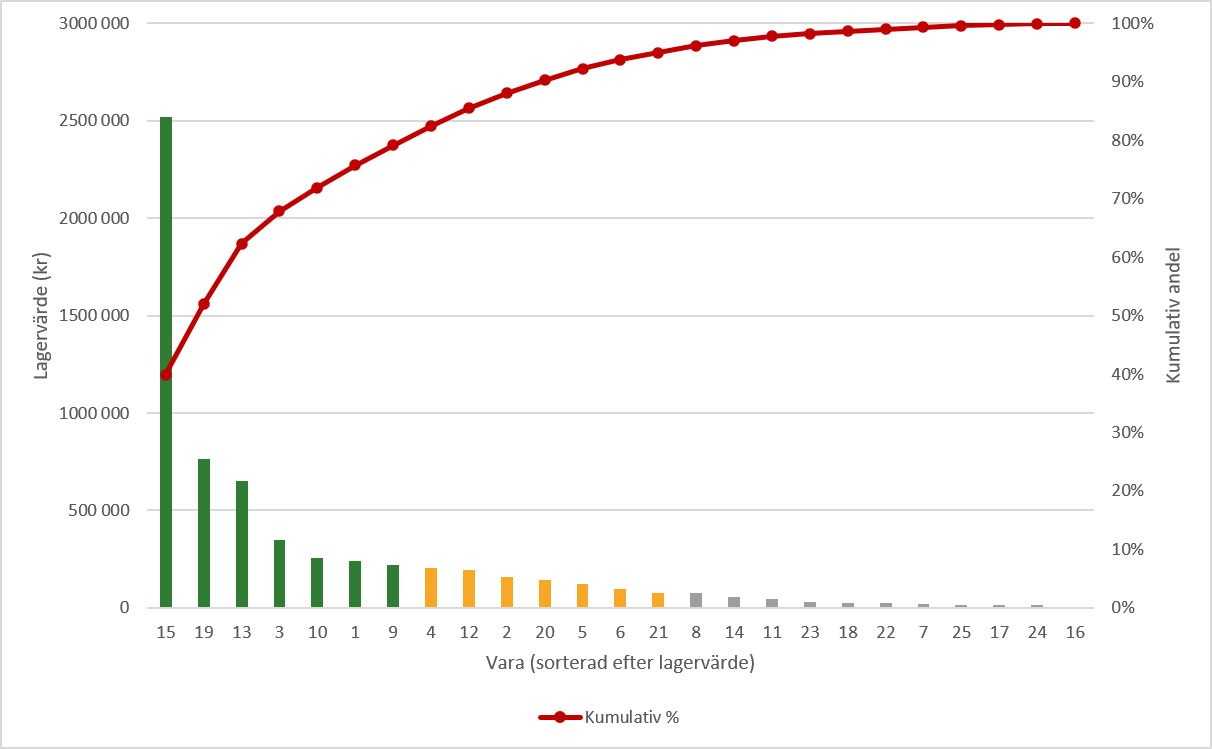

*Figur 1. Paretodiagram över ABC-analysen, gjort i Excel.*

---
# 2. Heltalsprogrammering 

Fyra personer kan utföra sex arbetsuppgifter. Person $i$ som gör uppgift $j$ ger vinsten $V_{ij}$. Varje uppgift får göras av högst en person. Varje person har ett begränsat antal dagar, och alla uppgifter tar lika lång tid för en och samma person.

## 2a) Generell matematisk modell

**Mängder**
- $I = \{1,2,3,4\}$: personer
- $J = \{1,2,3,4,5,6\}$: arbetsuppgifter

**Parametrar**
- $V_{ij}$: vinst om person $i$ utför uppgift $j$ (kr)
- $t_i$: antal dagar det tar för person $i$ att utföra en uppgift, $t = (2, 3, 3, 4)$
- $T_i$: antal tillgängliga dagar för person $i$, $T = (4, 4, 8, 8)$

**Beslutsvariabler**

$$x_{ij} = \begin{cases} 1 & \text{om person } i \text{ utför uppgift } j \\ 0 & \text{annars} \end{cases}$$

**Modell**

$$\max\; Z = \sum_{i \in I}\sum_{j \in J} V_{ij}\,x_{ij}$$

då

$$\sum_{i \in I} x_{ij} \le 1 \qquad \forall j \in J \qquad \text{(varje uppgift görs av högst en person)}$$

$$\sum_{j \in J} t_i\,x_{ij} \le T_i \qquad \forall i \in I \qquad \text{(personens tillgängliga tid)}$$

$$x_{ij} \in \{0,1\} \qquad \forall i \in I,\ j \in J$$

Det är ett generaliserat tilldelningsproblem, en person kan få flera uppgifter, så länge tiden räcker. Det är ett binärt heltalsproblem (BIP).


### Lösning

modell löses här i Python med 

In [234]:
from scipy.optimize import milp, LinearConstraint, Bounds

V = np.array([[37000, 23000, 20000, 18000, 16000,  6000],   
              [25000, 14000, 14000, 18000, 17000,  8000],
              [ 5000, 13000, 10000, 12000,  5000,  5000],
              [10000,  3000, 13000,  7000,  2000, 16000]])
t = np.array([2, 3, 3, 4])          # dagar per uppgift för person i
personer = [f"Person {i+1}" for i in range(4)]
uppgifter = [f"Uppgift {j+1}" for j in range(6)]


## 2b) Person 1 får 6 dagar

Enda ändringen i modellen är högerledet i tidsbivillkoret för person 1. Nu hinner person 1 göra 3 uppgifter.

---
# 3. Omlastningsmodell: probabilistiska bivillkor och heltal

### 3a) Nätverk och definitioner
### 3b) Generell modell
### 3c) Lösning med medelefterfrågan
### 3d) Probabilistiska bivillkor (90 %)
### 3e) Fasta kostnader för bruken
### 3f) Kapacitet på länkarna och heltal

---
# 4. Intermodal transportplanering

### 4a) Generell modell
### 4b) En färja (2000 lastbilar/år)
### 4c) Fler färjor
### 4d) Minskad kapacitet på vägen 2–3

---
# 5. Tomma godsvagnar

### 5a) Nätverk och modelltyp
### 5b) Generell modell
### 5c) Lösning
### 5d) Med och utan trängselvillkor
### 5e) Känslighet för P